In [1]:
import os
import pandas as pd
import scanpy as sc
from scipy.io import mmread
import anndata
import numpy as np

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
old_pd = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/weinreb/stateFate_inVitro_normed_counts.mtx')



In [3]:
old_pd.shape

(130887, 25289)

In [4]:
old_pd.X.max()

870.98303

In [5]:
clonal_info = mmread("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/weinreb/stateFate_inVitro_clone_matrix.mtx")

In [6]:
clonal_info.shape #all cells and all unique barcodes 

(130887, 5864)

In [7]:
np.sum(clonal_info, axis=1).max()

1

In [8]:
old_pd.obs["barcode"] = None

for cell in range(clonal_info.row.shape[0]): #going trough all cells that have a barcode
    old_pd.obs["barcode"][clonal_info.row[cell]] = clonal_info.col[cell]

In [9]:
gene_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/weinreb/stateFate_inVitro_gene_names.txt", header=None)

In [10]:
old_pd.var_names = gene_names[0]

In [11]:
adata = old_pd

In [12]:
import scanpy as sc
import numpy as np

# --- 1) Compute mitochondrial percentage ---
# Identify mitochondrial genes (human or mouse)
adata.var['mt'] = adata.var_names.str.upper().str.startswith('MT-')

# Calculate percentage
adata.obs['pct_mt'] = np.sum(
    adata[:, adata.var['mt']].X, axis=1
) / np.sum(adata.X, axis=1) * 100

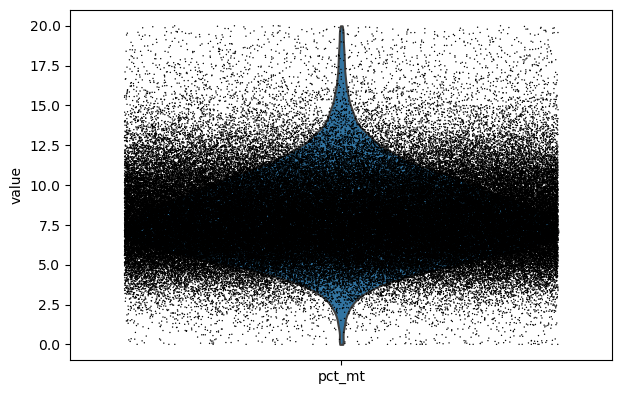

In [13]:
sc.pl.violin(adata, 'pct_mt', jitter=0.4)


In [14]:
# not filtering more since authors already applied filtering at 20%


In [15]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [16]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/scanpy/preprocessing/_simple.py:140: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['n_genes'] = number


In [17]:
adata_no_nan

AnnData object with n_obs × n_vars = 49302 × 22636
    obs: 'barcode', 'pct_mt', 'n_genes'
    var: 'mt', 'n_cells'

In [18]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
#sc.pp.log1p(adata_no_nan)

adata_filtered = adata_no_nan

In [19]:
adata_filtered.obs["barcode"] = adata_filtered.obs["barcode"].astype("str")

In [20]:
adata_filtered.obs_names

Index(['0', '1', '2', '4', '6', '8', '13', '14', '15', '16',
       ...
       '130866', '130869', '130872', '130873', '130874', '130875', '130876',
       '130877', '130879', '130883'],
      dtype='object', length=49302)

In [21]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [22]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [23]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [24]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [25]:
df

,0610006L08Rik,0610007P14Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik,0610009O20Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012D04Rik,...,mt-Cytb,mt-Nd1,mt-Nd2,mt-Nd3,mt-Nd4,mt-Nd4l,mt-Nd5,mt-Nd6,barcode,barcode_cont
0,0.0,1.260001,0.000000,0.0,0.0,0.630001,0.0,0.0,0.000000,0.0,...,51.660053,104.580101,25.200024,5.670006,56.070053,0.630001,12.600012,0.00000,573,0
1,0.0,0.000000,1.077702,0.0,0.0,0.000000,0.0,0.0,2.155404,0.0,...,40.952682,116.391838,26.942554,5.388511,65.739830,0.000000,5.388511,0.00000,1440,1
2,0.0,0.000000,1.673640,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,61.924675,117.154793,23.430958,6.694560,51.882839,1.673640,5.020920,1.67364,394,2
3,0.0,0.000000,5.670541,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,53.870140,102.069740,8.505812,0.000000,48.199600,2.835271,17.011623,0.00000,1972,3
4,0.0,2.231147,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,51.316368,55.778664,20.080318,13.386878,37.929489,0.000000,6.693439,0.00000,1450,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49297,0.0,2.269632,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,36.314117,99.863815,22.696323,9.078529,40.853382,2.269632,6.808897,0.00000,12,4997
49298,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,59.245392,118.490784,49.890858,3.118179,77.954468,6.236357,15.590893,0.00000,267,4847
49299,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,88.315216,57.744564,33.967392,6.793478,81.521744,0.000000,13.586956,0.00000,3534,3893
49300,0.0,4.302926,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,55.938030,94.664360,30.120478,8.605851,68.846809,0.000000,8.605851,0.00000,4945,4945


In [26]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [27]:
df.drop(columns = ["barcode"], inplace = True)

In [28]:
df

,0610006L08Rik,0610007P14Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik,0610009O20Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012D04Rik,...,mt-Co3,mt-Cytb,mt-Nd1,mt-Nd2,mt-Nd3,mt-Nd4,mt-Nd4l,mt-Nd5,mt-Nd6,barcode_cont
0,0.0,1.260001,0.000000,0.0,0.0,0.630001,0.0,0.0,0.000000,0.0,...,21.420021,51.660053,104.580101,25.200024,5.670006,56.070053,0.630001,12.600012,0.00000,0
1,0.0,0.000000,1.077702,0.0,0.0,0.000000,0.0,0.0,2.155404,0.0,...,23.709448,40.952682,116.391838,26.942554,5.388511,65.739830,0.000000,5.388511,0.00000,1
2,0.0,0.000000,1.673640,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,16.736399,61.924675,117.154793,23.430958,6.694560,51.882839,1.673640,5.020920,1.67364,2
3,0.0,0.000000,5.670541,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,31.187977,53.870140,102.069740,8.505812,0.000000,48.199600,2.835271,17.011623,0.00000,3
4,0.0,2.231147,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,22.311464,51.316368,55.778664,20.080318,13.386878,37.929489,0.000000,6.693439,0.00000,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49297,0.0,2.269632,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,13.617794,36.314117,99.863815,22.696323,9.078529,40.853382,2.269632,6.808897,0.00000,4997
49298,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,6.236357,59.245392,118.490784,49.890858,3.118179,77.954468,6.236357,15.590893,0.00000,4847
49299,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,16.983696,88.315216,57.744564,33.967392,6.793478,81.521744,0.000000,13.586956,0.00000,3893
49300,0.0,4.302926,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,25.817551,55.938030,94.664360,30.120478,8.605851,68.846809,0.000000,8.605851,0.00000,4945


In [29]:
df.to_pickle("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_nolog/weinreb_all_genes_nolog.pkl")

